### Validação de Clusters: Agrupamento Hierárquico

> **Nota de revisão:** a primeira versão deste notebook escolhia o `linkage` só pelo Coeficiente de Correlação Cofenética (CPCC) e o `k` só pela silhueta, sem nenhuma restrição de tamanho. Resultado: o `average` linkage isolou **2 municípios muito extremos** em um cluster próprio e jogou os outros 5568 em um único cluster — silhueta alta, mas um agrupamento inútil como subconjunto de treino. A versão abaixo primeiro identifica esses municípios atípicos separadamente e só então escolhe `linkage`/`k` com uma restrição de tamanho mínimo por cluster.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

base_path = Path.cwd().parent
file_path = base_path / "data" / "processed" / "Base_de_Dados_Treino.csv"

df = pd.read_csv(file_path, index_col="id_municipio")

df.head()

,População_2022,Pontuação Indice ODS 2025,Goal 1 Score,Goal 2 Score,Goal 3 Score,Goal 5 Score,Goal 6 Score,Goal 7 Score,Goal 8 Score,Goal 9 Score,...,Normalizado (0-100): SDG15_8_UNI_CNS,Normalizado (0-100): SDG15_PRTAMB,Normalizado (0-100): SDG16_1_OB_HM,Normalizado (0-100): SDG16_3_M_ARM_FG,Normalizado (0-100): SDG16_4_TX_HMC,Normalizado (0-100): SDG16_CRP,Normalizado (0-100): SDG16_DRTHMN,Normalizado (0-100): SDG16_TRANSP,Normalizado (0-100): SDG17_1_INVST_PB,Normalizado (0-100): SDG17_3_P_RC_TRB
id_municipio,,,,,,,,,,,,,,,,,,,,,
3918,13909.0,53.269415,59.155521,38.091787,64.289521,59.669159,64.310097,83.218333,45.514930,9.682504,...,0.000,80.0,0.0,0.0,43.239474,57.143,42.857,50.000,10.124436,13.564593
3986,21079.0,55.585523,46.276918,42.283804,69.059248,67.296407,60.647976,85.062037,55.873860,8.445009,...,0.000,80.0,100.0,0.0,75.039474,71.429,57.143,66.667,16.432705,15.811404
2758,8179.0,55.058278,50.879872,49.291735,71.076996,53.381715,60.523228,91.672593,61.346097,5.863289,...,0.021,80.0,100.0,100.0,100.000000,71.429,28.571,66.667,65.825616,21.501196
4797,2526.0,55.060949,62.635812,38.882979,72.896892,60.433893,66.063390,72.817500,58.852291,23.074656,...,0.000,80.0,100.0,100.0,100.000000,85.714,28.571,66.667,41.141996,7.627592
4504,6716.0,50.710311,46.935921,39.611815,78.407745,72.821067,60.823721,70.107870,56.257037,16.999769,...,0.000,60.0,100.0,100.0,100.000000,85.714,57.143,66.667,12.527347,10.809410


Separação através das features escolhidas

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

import json

with open(base_path / "data" / "processed" / "features_perfil.json", encoding="utf-8") as f:
    features_perfil = json.load(f)

X_perfil = df[features_perfil].copy()

imputer_perfil = SimpleImputer(strategy='median')
X_perfil_imputed = pd.DataFrame(imputer_perfil.fit_transform(X_perfil), columns=features_perfil)

scaler_perfil = StandardScaler()
X_perfil_scaled = scaler_perfil.fit_transform(X_perfil_imputed)

#### 1.0 Detecção de municípios atípicos (outliers)

Municípios muito extremos em relação a todos os outros distorcem a escolha de `linkage`/`k`: como estão longe de tudo, isolá-los em um cluster próprio maximiza artificialmente a silhueta, mesmo sendo um agrupamento sem utilidade prática (um cluster com 2 municípios não serve como subconjunto de treino). Isso é o efeito de *chaining*, mais comum nos linkages `average`/`single`/`complete`, mas que pode acontecer mesmo no `ward` quando os pontos são extremos o suficiente.

Em vez de deixar o clustering lidar com isso, identificamos esses municípios **antes**: calculamos a distância média de cada um aos seus `K_VIZINHOS` vizinhos mais próximos (espaço padronizado) e aplicamos a regra de Tukey (`Q3 + 1.5×IQR`) sobre essa distribuição — quem tem uma vizinhança anormalmente distante é sinalizado como atípico e recebe o rótulo `-1` ("Atípico"), no mesmo espírito do ruído do DBSCAN. O agrupamento principal é então feito só com os municípios restantes ('núcleo' dos dados).

In [3]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

K_VIZINHOS = 10

nn = NearestNeighbors(n_neighbors=K_VIZINHOS + 1).fit(X_perfil_scaled)
distancias_vizinhos, _ = nn.kneighbors(X_perfil_scaled)
dist_media_knn = distancias_vizinhos[:, 1:].mean(axis=1)  # exclui a distância a si mesmo (0)

q1, q3 = np.percentile(dist_media_knn, [25, 75])
iqr = q3 - q1
limiar_outlier = q3 + 1.5 * iqr

mask_outlier = dist_media_knn > limiar_outlier
print(f"Municípios sinalizados como atípicos: {mask_outlier.sum()} de {len(df)} ({mask_outlier.mean():.1%})")

Municípios sinalizados como atípicos: 107 de 4456 (2.4%)


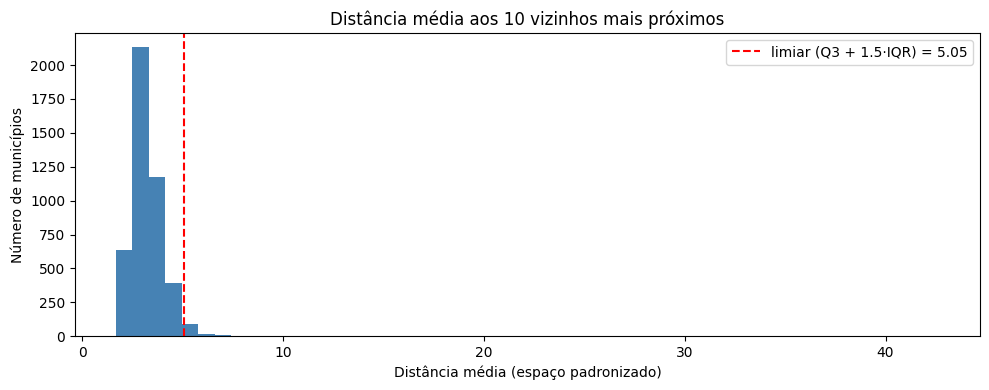

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(dist_media_knn, bins=50, color='steelblue')
ax.axvline(limiar_outlier, color='r', linestyle='--',
           label=f'limiar (Q3 + 1.5·IQR) = {limiar_outlier:.2f}')
ax.set_title(f'Distância média aos {K_VIZINHOS} vizinhos mais próximos')
ax.set_xlabel('Distância média (espaço padronizado)')
ax.set_ylabel('Número de municípios')
ax.legend()
plt.tight_layout()
plt.show()

#### 1.1 Escolha do *linkage* e do número de clusters (com restrição de tamanho mínimo)

Agora sim escolhemos `linkage` e `k` juntos, testando os 4 métodos de linkage combinados com `k` de 2 a 10 — **apenas nos municípios do núcleo** (sem os atípicos já removidos acima). Para cada combinação calculamos o CPCC (fidelidade às distâncias originais), o silhouette score e o **tamanho do menor cluster** formado. Só entram na disputa pela maior silhueta as combinações em que todo cluster tem pelo menos `min_tamanho_cluster` municípios — isso impede que o algoritmo repita o problema do notebook anterior, mesmo já sem os outliers mais extremos.

> **Nota de revisão 2:** mesmo removendo os atípicos, `average` (e o mesmo vale para `single`) continua vencendo pela silhueta com apenas `k = 2` (ou `k = 3`, com silhueta ainda menor) — porque esses linkages fazem *chaining*: preferem descascar um bolsão de municípios um pouco mais afastados do resto e jogar a maioria absoluta num único cluster gigante. Isolar um grupo pequeno e periférico do resto sempre maximiza a silhueta aparente, mesmo sem gerar uma segmentação útil como base para múltiplos subconjuntos de treino.

Por isso a seleção abaixo passa a exigir **duas** restrições, não só o tamanho mínimo por cluster: também um **`k` mínimo** (`MIN_K`), para forçar o critério a considerar apenas soluções que de fato dividem os dados em vários grupos. Também calculamos a **razão de balanceamento** (`tamanho do menor cluster / tamanho do maior`) só para leitura — não entra na escolha, mas ajuda a enxergar quando um linkage está isolando bolsões pequenos em vez de segmentar de verdade.

In [5]:
X_core_scaled = X_perfil_scaled[~mask_outlier]
dist_condensada_core = pdist(X_core_scaled)

metodos_linkage = ['ward', 'complete', 'average', 'single']
k_range = range(2, 11)

MIN_FRACAO_CLUSTER = 0.02
min_tamanho_cluster = max(30, int(len(X_core_scaled) * MIN_FRACAO_CLUSTER))

MIN_K = 4  # exige uma segmentação com pelo menos 4 grupos -- não só tamanho mínimo por grupo

print(f"Tamanho mínimo exigido por cluster: {min_tamanho_cluster} municípios "
      f"({MIN_FRACAO_CLUSTER:.0%} dos {len(X_core_scaled)} municípios do núcleo)")
print(f"Número mínimo de clusters exigido: {MIN_K}")

resultados_hier = []
for metodo in metodos_linkage:
    Z = linkage(X_core_scaled, method=metodo)
    coef_cofenetico, _ = cophenet(Z, dist_condensada_core)
    for k in k_range:
        labels_k = AgglomerativeClustering(n_clusters=k, linkage=metodo).fit_predict(X_core_scaled)
        contagens = pd.Series(labels_k).value_counts()
        tamanho_min = contagens.min()
        tamanho_max = contagens.max()
        sil = silhouette_score(X_core_scaled, labels_k)
        resultados_hier.append({
            'linkage': metodo,
            'k': k,
            'cpcc': coef_cofenetico,
            'tamanho_min_cluster': tamanho_min,
            'razao_balanceamento': tamanho_min / tamanho_max,
            'silhouette': sil
        })

df_resultados_hier = pd.DataFrame(resultados_hier)

validos_hier = df_resultados_hier[
    (df_resultados_hier['tamanho_min_cluster'] >= min_tamanho_cluster) &
    (df_resultados_hier['k'] >= MIN_K)
]

if validos_hier.empty:
    print(f"\nNenhuma combinação atingiu tamanho mínimo por cluster COM k >= {MIN_K}.")
    print("Relaxando a exigência de k mínimo (mantendo o tamanho mínimo por cluster)...")
    validos_hier = df_resultados_hier[df_resultados_hier['tamanho_min_cluster'] >= min_tamanho_cluster]

if validos_hier.empty:
    print("\nAinda vazio -- usando a combinação de maior 'menor cluster' disponível, ignorando os dois filtros.")
    validos_hier = df_resultados_hier.sort_values('tamanho_min_cluster', ascending=False)

validos_hier = validos_hier.sort_values('silhouette', ascending=False)
display(validos_hier.head(10))

melhor_linha = validos_hier.iloc[0]
melhor_linkage = melhor_linha['linkage']
melhor_k_hier = int(melhor_linha['k'])
print(f"\nEscolhido: linkage = {melhor_linkage}, k = {melhor_k_hier} "
      f"(silhouette = {melhor_linha['silhouette']:.4f}, menor cluster = {int(melhor_linha['tamanho_min_cluster'])} municípios, "
      f"razão de balanceamento = {melhor_linha['razao_balanceamento']:.3f})")

Tamanho mínimo exigido por cluster: 86 municípios (2% dos 4349 municípios do núcleo)
Número mínimo de clusters exigido: 4


,linkage,k,cpcc,tamanho_min_cluster,razao_balanceamento,silhouette
2,ward,4,0.443312,215,0.073655,0.089139
4,ward,6,0.443312,93,0.031860,0.086480
5,ward,7,0.443312,93,0.031860,0.084487
3,ward,5,0.443312,188,0.064406,0.079564
6,ward,8,0.443312,93,0.038961,0.064631
7,ward,9,0.443312,93,0.055722,0.062008



Escolhido: linkage = ward, k = 4 (silhouette = 0.0891, menor cluster = 215 municípios, razão de balanceamento = 0.074)


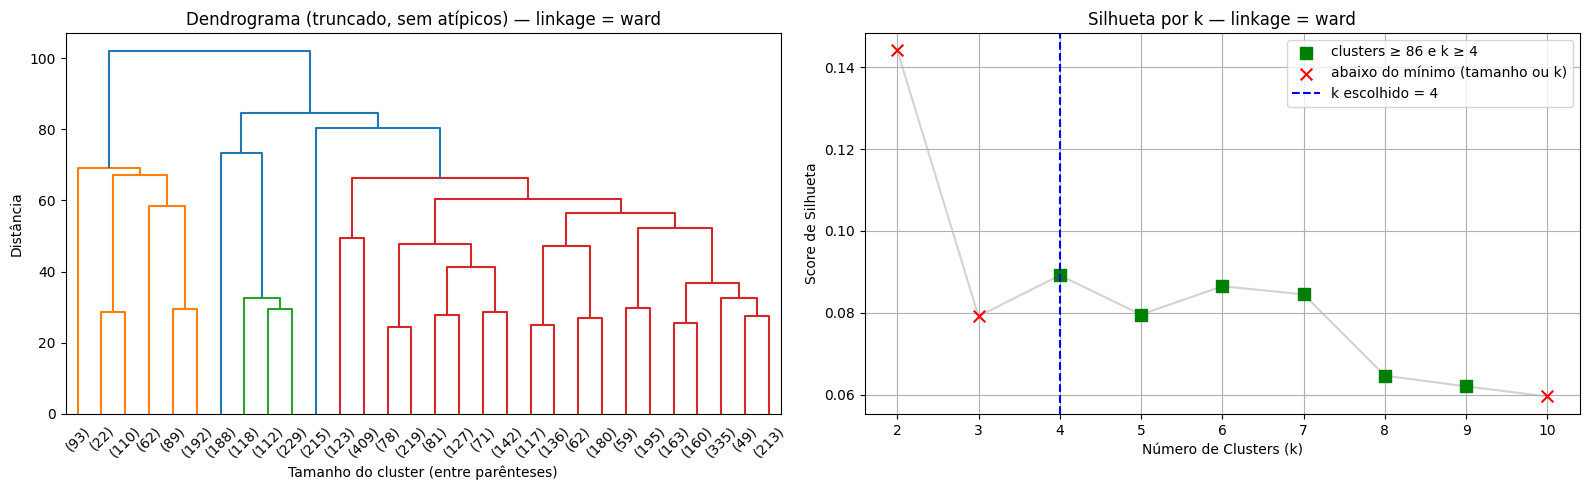

In [6]:
Z_melhor = linkage(X_core_scaled, method=melhor_linkage)

subset_linkage = df_resultados_hier[df_resultados_hier['linkage'] == melhor_linkage].sort_values('k')
mascara_validos = (subset_linkage['tamanho_min_cluster'] >= min_tamanho_cluster) & (subset_linkage['k'] >= MIN_K)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

dendrogram(Z_melhor, truncate_mode='lastp', p=30, ax=ax1)
ax1.set_title(f'Dendrograma (truncado, sem atípicos) — linkage = {melhor_linkage}')
ax1.set_xlabel('Tamanho do cluster (entre parênteses)')
ax1.set_ylabel('Distância')

ax2.plot(subset_linkage['k'], subset_linkage['silhouette'], linestyle='-', color='lightgray', zorder=1)
ax2.scatter(subset_linkage.loc[mascara_validos, 'k'], subset_linkage.loc[mascara_validos, 'silhouette'],
            color='g', marker='s', s=70, label=f'clusters ≥ {min_tamanho_cluster} e k ≥ {MIN_K}', zorder=2)
ax2.scatter(subset_linkage.loc[~mascara_validos, 'k'], subset_linkage.loc[~mascara_validos, 'silhouette'],
            color='r', marker='x', s=70, label='abaixo do mínimo (tamanho ou k)', zorder=2)
ax2.axvline(melhor_k_hier, color='b', linestyle='--', label=f'k escolhido = {melhor_k_hier}')
ax2.set_title(f'Silhueta por k — linkage = {melhor_linkage}')
ax2.set_xlabel('Número de Clusters (k)')
ax2.set_ylabel('Score de Silhueta')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

Execução do algoritmo de agrupamento

In [7]:
agglo_perfil = AgglomerativeClustering(n_clusters=melhor_k_hier, linkage=melhor_linkage)
labels_core = agglo_perfil.fit_predict(X_core_scaled)

# reconstrói o vetor de rótulos no tamanho original do df:
# municípios atípicos recebem -1 ("Atípico"), os demais recebem o cluster do núcleo
labels_perfil_hier = np.full(len(df), -1, dtype=int)
labels_perfil_hier[~mask_outlier] = labels_core

df['Cluster_Perfil_Hierarquico'] = labels_perfil_hier

Média de cada variável por cluster

O cluster `-1` corresponde aos municípios atípicos, sinalizados antes do agrupamento — deve ser interpretado como "atípico", não como um perfil coeso.

In [8]:
df_analise_perfis_hier = X_perfil_imputed.copy()
df_analise_perfis_hier['Cluster'] = labels_perfil_hier

resumo_perfis_hier = df_analise_perfis_hier.groupby('Cluster').mean().round(2)
display(resumo_perfis_hier)

df_analise_perfis_hier['Cluster'].value_counts().sort_index()

,Goal 12 Score,Goal 13 Score,Goal 15 Score,Goal 2 Score,Normalizado (0-100): SDG10_21_GRV,Normalizado (0-100): SDG10_4_ACEQP,Normalizado (0-100): SDG10_DIF_FEM_NNN,Normalizado (0-100): SDG11_33_M_TRNS,Normalizado (0-100): SDG11_4_P_P_SUBN,Normalizado (0-100): SDG11_6_NGR_SUBN,...,Normalizado (0-100): SDG2_9_AGR_ORG,Normalizado (0-100): SDG3_13_SCD,Normalizado (0-100): SDG3_16_M_MAT,Normalizado (0-100): SDG3_18_T_M_NT,Normalizado (0-100): SDG5_4_P_VRDR,Normalizado (0-100): SDG5_7_JV_NENT,Normalizado (0-100): SDG6_1_IN_DRSAI,Normalizado (0-100): SDG6_8_CLT_DML,Normalizado (0-100): SDG8_2_OCP_INF,Pontuação Indice ODS 2025
Cluster,,,,,,,,,,,,,,,,,,,,,
-1,73.22,62.53,27.79,47.78,55.87,86.51,78.93,70.54,81.20,2.17,...,17.75,69.33,68.61,69.48,25.38,45.94,66.97,74.43,63.99,47.45
0,72.77,64.71,22.64,46.65,57.43,99.93,26.41,63.98,98.61,0.00,...,2.98,78.85,75.62,74.31,1.98,40.76,72.48,75.39,61.95,46.10
1,62.90,72.99,29.99,47.24,64.98,83.20,66.97,76.07,76.51,0.01,...,18.19,80.55,94.24,77.14,1.67,51.19,86.61,85.21,70.62,51.16
2,74.12,66.18,21.38,46.42,56.01,99.87,98.91,65.85,99.52,0.00,...,3.64,76.63,99.18,77.73,2.76,43.97,76.02,75.81,57.97,50.71
3,74.77,66.84,21.40,46.34,53.02,99.68,84.83,64.07,99.61,0.00,...,2.98,77.29,98.98,76.69,77.25,44.04,78.26,79.98,56.13,51.03


Cluster
-1     107
 0     647
 1     568
 2    2919
 3     215
Name: count, dtype: int64

Perfil de Município

In [9]:
clusters_validos_hier = sorted(c for c in df['Cluster_Perfil_Hierarquico'].unique() if c != -1)
nomes_perfis_hier = {c: f'Perfil {i+1}' for i, c in enumerate(clusters_validos_hier)}
nomes_perfis_hier[-1] = 'Atípico'

df['Nome_Perfil_Hierarquico'] = df['Cluster_Perfil_Hierarquico'].map(nomes_perfis_hier)

display(df['Nome_Perfil_Hierarquico'].value_counts())

Nome_Perfil_Hierarquico
Perfil 3    2919
Perfil 1     647
Perfil 2     568
Perfil 4     215
Atípico      107
Name: count, dtype: int64

#### Geração dos subconjuntos de treino por cluster (Hierárquico)

Inclui também o cluster `-1` (Atípico) como um subconjunto próprio — ver nota abaixo sobre o que isso implica para a atribuição do conjunto de teste no notebook 07.

In [10]:
dir_saida = base_path / "data" / "processed" / "subconjuntos" / "hierarquico"
dir_saida.mkdir(parents=True, exist_ok=True)

# base de treino completa (TODAS as features, não só as usadas no clustering) rotulada com o cluster
df.to_csv(dir_saida / "treino_rotulado.csv", index_label="id_municipio")

clusters_encontrados = sorted(df['Cluster_Perfil_Hierarquico'].unique())
print(f"Clusters encontrados: {clusters_encontrados}")

for cluster_id in clusters_encontrados:
    subconjunto = df[df['Cluster_Perfil_Hierarquico'] == cluster_id]
    nome_arquivo = f"cluster_{cluster_id}.csv"
    subconjunto.to_csv(dir_saida / nome_arquivo, index_label="id_municipio")
    print(f"  cluster {cluster_id}: {len(subconjunto)} municípios -> {dir_saida / nome_arquivo}")

print(f"\nSubconjuntos salvos em: {dir_saida}")

Clusters encontrados: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
  cluster -1: 107 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/hierarquico/cluster_-1.csv
  cluster 0: 647 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/hierarquico/cluster_0.csv
  cluster 1: 568 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/hierarquico/cluster_1.csv
  cluster 2: 2919 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/hierarquico/cluster_2.csv
  cluster 3: 215 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/hierarquico/cluster_3.csv

Subconjuntos salvos em: /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/hierarquico
